# Predicción de abandono mensual de clientes — Pinturería
**Proyecto final · Data Science (Coderhouse)** — Pablo Ferres

Pipeline completo de Machine Learning: formulación del problema → EDA → ingeniería de atributos → entrenamiento y optimización → selección y evaluación → interpretabilidad con SHAP.

**Índice**
1. Configuración y reproducibilidad
2. Formulación del problema
3. Carga de datos y control de calidad
4. Análisis exploratorio (EDA)
5. Ingeniería de atributos: panel cliente-mes
6. Exploración del dataset de modelado
7. Esquema de validación temporal
8. Entrenamiento y optimización de hiperparámetros
9. Selección y evaluación del modelo
10. Interpretabilidad con SHAP
11. Conclusiones, recomendaciones y limitaciones

## 1. Configuración y reproducibilidad

In [1]:
# --- Librerías ---
import json
import platform
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import xgboost
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             RocCurveDisplay, confusion_matrix, roc_auc_score)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# --- Rutas: el notebook funciona tanto desde la raíz del repo como desde /notebooks ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "processed" / "ventas_anonimizado.csv"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

from src.features import (FEATURES_CAT, FEATURES_NUM, TARGET, cargar_ventas,
                          construir_panel)
from src.modelado import (crear_preprocesador, cv_ventana_expansiva, metricas,
                          split_temporal, umbral_para_recall)

# --- Semilla global ---
SEED = 42
np.random.seed(SEED)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=120, bbox_inches="tight")

print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} "
      f"| xgboost {xgboost.__version__} | shap {shap.__version__}")

Python 3.12.3 | pandas 3.0.2 | scikit-learn 1.8.0 | xgboost 3.4.1 | shap 0.54.1


## 2. Formulación del problema

**Contexto de negocio.** La pinturería vende a consumidores finales y a una cartera de ~300 clientes identificados (pintores, constructoras, empresas). Estos clientes compran de forma irregular, y el local no tiene hoy una forma sistemática de detectar quiénes están dejando de comprar.

**Tarea:** clasificación binaria supervisada.

**Unidad de análisis:** cliente identificado × mes (se excluye "Consumidor Final", que agrupa a compradores anónimos).

**Variable objetivo — `churn_mes_siguiente`:** al cierre de cada mes *t*, vale **1** si el cliente **no** realiza ninguna compra (factura o ticket) en el mes *t+1*, y **0** si vuelve a comprar.

**Métricas de éxito:**
- **ROC-AUC (métrica principal de selección):** mide la capacidad del modelo de *ordenar* a los clientes por riesgo, independientemente del umbral. Es lo que necesita el área comercial: una lista priorizada.
- **PR-AUC:** complementa a ROC-AUC con foco en la clase positiva.
- **Recall de churn ≥ 80 % con la máxima precisión posible (punto de operación):** contactar a un cliente (WhatsApp, llamado del vendedor, promo) es barato; perder un cliente recurrente es caro. Por eso se prioriza no dejar escapar a los que se van.

**Criterio de éxito:** superar claramente a una regla simple de negocio basada en la recencia (días desde la última compra), con ROC-AUC > 0,80 en un período de test posterior al de entrenamiento.

## 3. Carga de datos y control de calidad

**Fuente:** sistema de facturación de la pinturería, ventas línea por línea de **enero a diciembre de 2025**. El dataset publicado está **anonimizado** con `src/anonimizar.py` (sin nombres de clientes ni vendedores; códigos de cliente reemplazados por hash).

In [2]:
ventas = cargar_ventas(DATA)
print(f"Filas: {len(ventas):,} | Columnas: {ventas.shape[1]}")
print(f"Período: {ventas['FECHA'].min():%d/%m/%Y} a {ventas['FECHA'].max():%d/%m/%Y}")
print(f"Comprobantes: {ventas['ID_COMPROBANTE'].nunique():,} | Clientes: {ventas['ID_CLIENTE'].nunique()} "
      f"| Artículos: {ventas['COD ARTICULO'].nunique():,}")
ventas.head()

Filas: 24,954 | Columnas: 28
Período: 02/01/2025 a 26/12/2025
Comprobantes: 8,844 | Clientes: 299 | Artículos: 1,857


,FECHA,HORA,SUCURSAL,PUNTO DE VENTA,TIPO,LETRA,NUMERO COMPROBANTE,COD VENDEDOR,TIPO VENTA,MEDIO DE PAGO,...,PRECIO UNITARIO,DESCUENTO (%),RECARGO (%),PRECIO TOTAL,ID_CLIENTE,MES,ID_COMPROBANTE,COSTO_TOTAL,ES_COMPRA,ES_SINTEPLAST
0,2025-01-02,09:06:42,1,8,TK,A,5073,9,Mostrador,N/D,...,"12,339.890",0.250,0,"9,254.920",C_734ddf2247,2025-01,8-TK-A-5073,"6,169.940",True,1
1,2025-01-02,09:06:42,1,8,TK,A,5073,9,Mostrador,N/D,...,819.610,0.250,0,"2,458.830",C_734ddf2247,2025-01,8-TK-A-5073,"1,821.360",True,0
2,2025-01-02,09:06:42,1,8,TK,A,5073,9,Mostrador,N/D,...,819.610,0.250,0,"2,458.830",C_734ddf2247,2025-01,8-TK-A-5073,"1,821.360",True,0
3,2025-01-02,09:06:42,1,8,TK,A,5073,9,Mostrador,N/D,...,819.610,0.250,0,"2,458.830",C_734ddf2247,2025-01,8-TK-A-5073,"1,821.360",True,0
4,2025-01-02,09:06:42,1,8,TK,A,5073,9,Mostrador,N/D,...,819.610,0.250,0,"2,458.830",C_734ddf2247,2025-01,8-TK-A-5073,"1,821.360",True,0


In [3]:
# Tipos de dato y valores faltantes
calidad = pd.DataFrame({
    "tipo": ventas.dtypes.astype(str),
    "nulos": ventas.isna().sum(),
    "%_nulos": ventas.isna().mean() * 100,
    "valores_unicos": ventas.nunique(),
})
calidad[calidad.columns].sort_values("%_nulos", ascending=False)

,tipo,nulos,%_nulos,valores_unicos
MARCA,str,14006,56.127,1
COD MARCA,float64,14006,56.127,1
PROVEEDOR,str,903,3.619,48
COD PROVEEDOR,float64,903,3.619,48
TIPO,str,0,0.000,4
LETRA,str,0,0.000,2
NUMERO COMPROBANTE,int64,0,0.000,7921
COD VENDEDOR,int64,0,0.000,7
FECHA,datetime64[us],0,0.000,294
HORA,str,0,0.000,7511


In [4]:
# Chequeos de consistencia
chequeos = {
    "Columnas constantes (sin información)": [c for c in ventas.columns if ventas[c].nunique(dropna=False) == 1],
    "Filas duplicadas exactas": int(ventas.duplicated().sum()),
    "Líneas con CANTIDAD <= 0": int((ventas["CANTIDAD"] <= 0).sum()),
    "Líneas FC/TK con importe negativo": int(((ventas["ES_COMPRA"]) & (ventas["PRECIO TOTAL"] < 0)).sum()),
    "Líneas de nota de crédito (NC)": int((ventas["TIPO"] == "NC").sum()),
}
for k, v in chequeos.items():
    print(f"- {k}: {v}")

# Verificación del cálculo del precio total: unitario × cantidad × (1 - descuento)
recalculado = ventas["PRECIO UNITARIO"] * ventas["CANTIDAD"] * (1 - ventas["DESCUENTO (%)"])
dif = (recalculado - ventas["PRECIO TOTAL"]).abs()
print(f"- Líneas donde PRECIO TOTAL ≠ unitario × cant × (1 − desc) (dif > $1): {(dif > 1).sum()}")

- Columnas constantes (sin información): ['SUCURSAL', 'TIPO VENTA', 'MEDIO DE PAGO', 'RECARGO (%)']
- Filas duplicadas exactas: 436
- Líneas con CANTIDAD <= 0: 1550
- Líneas FC/TK con importe negativo: 82
- Líneas de nota de crédito (NC): 1073
- Líneas donde PRECIO TOTAL ≠ unitario × cant × (1 − desc) (dif > $1): 3361


**Problemas detectados y decisiones:**
- **Columnas constantes** (`SUCURSAL`, `TIPO VENTA`, `MEDIO DE PAGO`, `RECARGO (%)`): no aportan información y se descartan.
- **`MARCA`/`COD MARCA` ~56 % nulos:** el maestro de marcas sólo tiene cargada a Sinteplast. No es un faltante aleatorio: el nulo significa "otra marca". Se transforma en el indicador `ES_SINTEPLAST`.
- **`PROVEEDOR` ~4 % nulos:** artículos sin proveedor asignado en el maestro; no se usa como feature.
- **Duplicados exactos:** sin un ID de línea no se puede distinguir un error de carga de un mismo artículo escaneado dos veces en el ticket. Se conservan (su efecto sobre agregados mensuales es marginal).
- **`PRECIO TOTAL` no siempre coincide con unitario × cantidad × (1 − descuento)** (~13 % de las líneas): son NC con precio unitario y cantidad negativos a la vez, y artículos vendidos en fracciones (colorantes, por kg o litro) cuya cantidad se exportó redondeada a 2 decimales. Se toma `PRECIO TOTAL` como importe válido, porque es el que se facturó.
- **Cantidades e importes negativos en FC/TK:** corresponden a anulaciones o correcciones dentro del mismo comprobante. Se conservan porque netean el importe real de la compra.
- **Notas de crédito (NC):** son devoluciones/ajustes. No se cuentan como compras, pero sí se usan para el feature `pct_devoluciones`.

## 4. Análisis exploratorio (EDA)

### 4.1 Evolución mensual de las ventas

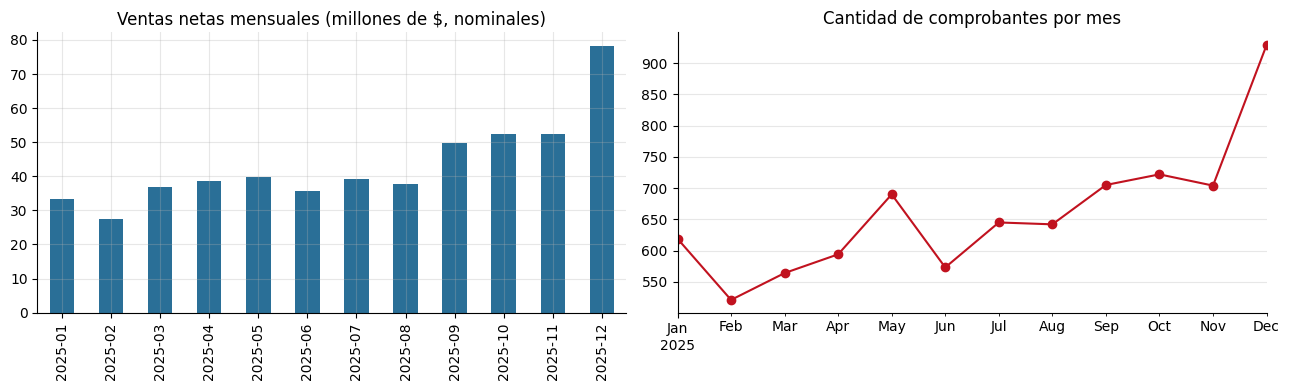

,ventas_netas,comprobantes,ticket_promedio
MES,,,
2025-01,"33,205,556.320",619,"53,643.871"
2025-02,"27,371,842.590",521,"52,537.126"
2025-03,"36,766,824.040",564,"65,189.404"
2025-04,"38,635,844.860",594,"65,043.510"
2025-05,"39,723,571.260",690,"57,570.393"
2025-06,"35,760,546.830",573,"62,409.331"
2025-07,"39,131,522.890",645,"60,669.028"
2025-08,"37,757,227.200",642,"58,811.880"
2025-09,"49,899,461.980",705,"70,779.379"


In [5]:
compras = ventas[ventas["ES_COMPRA"]]
mensual = compras.groupby("MES").agg(ventas_netas=("PRECIO TOTAL", "sum"),
                                     comprobantes=("ID_COMPROBANTE", "nunique"))
mensual["ticket_promedio"] = mensual["ventas_netas"] / mensual["comprobantes"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(mensual["ventas_netas"] / 1e6).plot(kind="bar", ax=ax[0], color="#2a6f97")
ax[0].set_title("Ventas netas mensuales (millones de $, nominales)"); ax[0].set_xlabel("")
mensual["comprobantes"].plot(ax=ax[1], marker="o", color="#c1121f", label="Comprobantes")
ax[1].set_title("Cantidad de comprobantes por mes"); ax[1].set_xlabel("")
guardar("01_ventas_mensuales")
plt.show()
mensual

**Insight:** la facturación nominal crece fuerte en el segundo semestre (diciembre es el pico), pero la cantidad de comprobantes crece mucho menos. Parte del crecimiento es **inflación** y aumento de ticket, no más operaciones. **Implicancia para el modelado:** los montos en pesos nominales no son comparables entre meses. Por eso los features monetarios se expresan **en relación con el total del local en el mismo período**.

### 4.2 Composición: tipo de comprobante, consumidor final y concentración de clientes

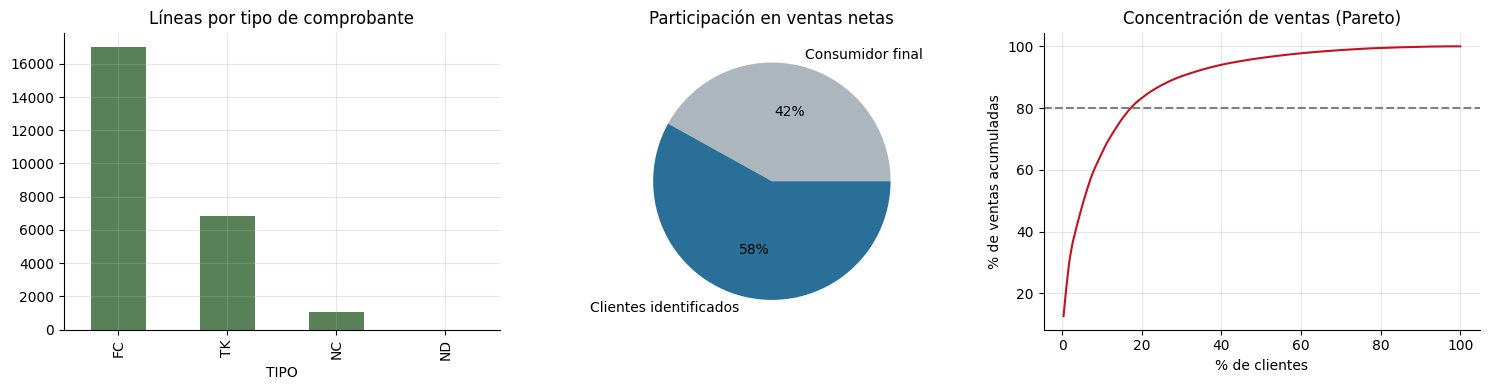

El 20 % de los clientes identificados explica el 83% de sus ventas.


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ventas["TIPO"].value_counts().plot(kind="bar", ax=ax[0], color="#588157")
ax[0].set_title("Líneas por tipo de comprobante")

es_cf = compras["ID_CLIENTE"] == "CONSUMIDOR_FINAL"
pd.Series({"Consumidor final": compras.loc[es_cf, "PRECIO TOTAL"].sum(),
           "Clientes identificados": compras.loc[~es_cf, "PRECIO TOTAL"].sum()}).plot(
    kind="pie", ax=ax[1], autopct="%1.0f%%", colors=["#adb5bd", "#2a6f97"], ylabel="")
ax[1].set_title("Participación en ventas netas")

# Curva de Pareto de clientes identificados
por_cliente = compras[~es_cf].groupby("ID_CLIENTE")["PRECIO TOTAL"].sum().sort_values(ascending=False)
acum = por_cliente.cumsum() / por_cliente.sum()
ax[2].plot(np.arange(1, len(acum) + 1) / len(acum) * 100, acum.values * 100, color="#c1121f")
ax[2].axhline(80, ls="--", c="grey"); ax[2].set_xlabel("% de clientes"); ax[2].set_ylabel("% de ventas acumuladas")
ax[2].set_title("Concentración de ventas (Pareto)")
guardar("02_composicion")
plt.show()

top20 = acum.iloc[int(len(acum) * 0.2) - 1]
print(f"El 20 % de los clientes identificados explica el {top20:.0%} de sus ventas.")

### 4.3 Comportamiento de compra de los clientes identificados

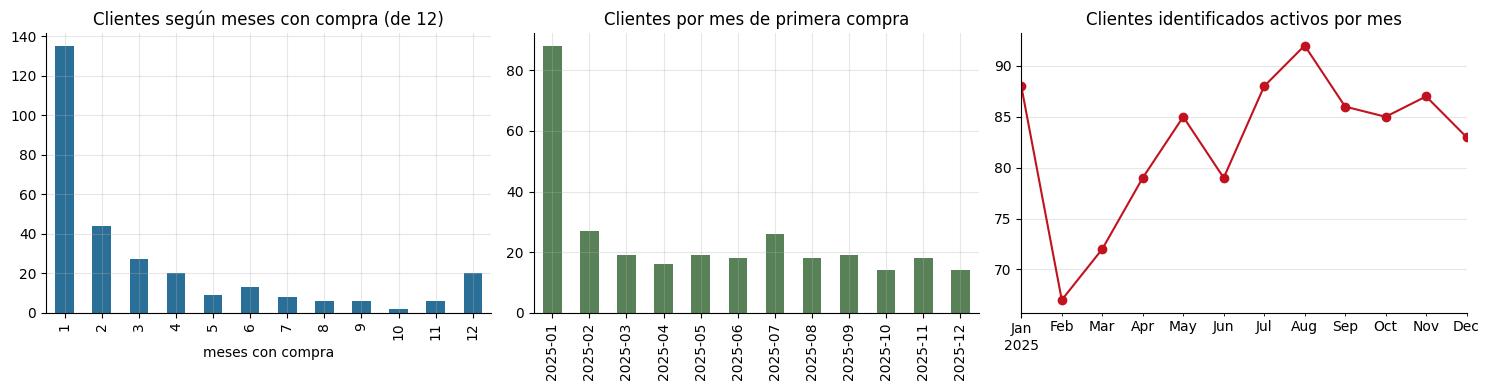

Clientes que compraron en un solo mes del año: 46%
Clientes que compraron en 6 meses o más: 21%


In [7]:
cli = compras[~es_cf]
meses_activos = cli.groupby("ID_CLIENTE")["MES"].nunique()
primer_mes = cli.groupby("ID_CLIENTE")["MES"].min()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
meses_activos.value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#2a6f97")
ax[0].set_title("Clientes según meses con compra (de 12)"); ax[0].set_xlabel("meses con compra")

primer_mes.value_counts().sort_index().plot(kind="bar", ax=ax[1], color="#588157")
ax[1].set_title("Clientes por mes de primera compra"); ax[1].set_xlabel("")

activos_mes = cli.groupby("MES")["ID_CLIENTE"].nunique()
activos_mes.plot(ax=ax[2], marker="o", color="#c1121f")
ax[2].set_title("Clientes identificados activos por mes"); ax[2].set_xlabel("")
guardar("03_comportamiento_clientes")
plt.show()

print(f"Clientes que compraron en un solo mes del año: {(meses_activos == 1).mean():.0%}")
print(f"Clientes que compraron en 6 meses o más: {(meses_activos >= 6).mean():.0%}")

### 4.4 Descuentos, márgenes y devoluciones

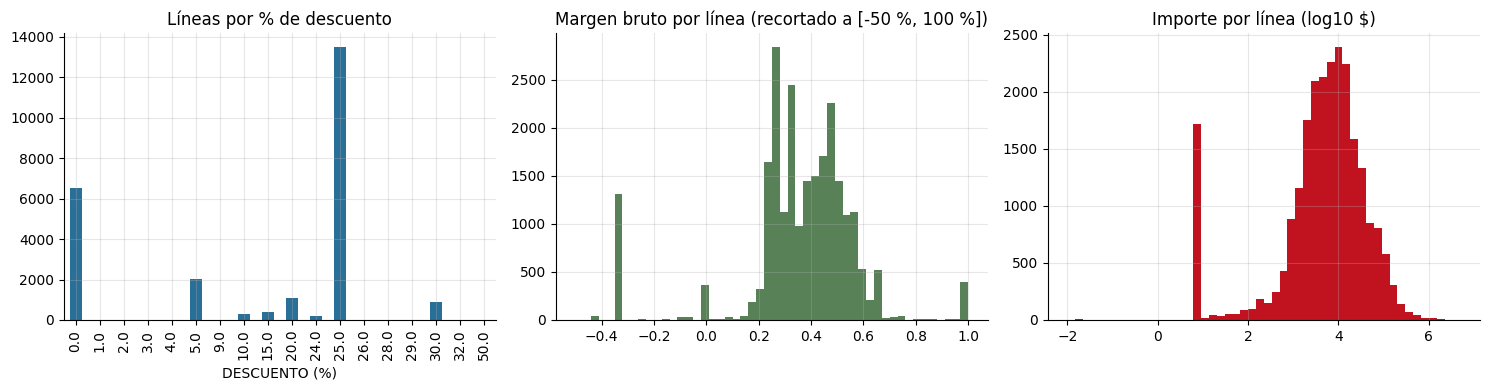

Margen bruto ponderado del período: 37.8%
Líneas con margen negativo (venta bajo costo): 6.1%


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ventas["DESCUENTO (%)"].mul(100).round().value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#2a6f97")
ax[0].set_title("Líneas por % de descuento")

c_ok = compras[compras["PRECIO TOTAL"] > 0]
margen_linea = (c_ok["PRECIO TOTAL"] - c_ok["COSTO_TOTAL"]) / c_ok["PRECIO TOTAL"]
margen_linea.clip(-0.5, 1).hist(bins=50, ax=ax[1], color="#588157")
ax[1].set_title("Margen bruto por línea (recortado a [-50 %, 100 %])")

np.log10(c_ok["PRECIO TOTAL"]).hist(bins=50, ax=ax[2], color="#c1121f")
ax[2].set_title("Importe por línea (log10 $)")
guardar("04_descuentos_margenes")
plt.show()

print(f"Margen bruto ponderado del período: {(c_ok['PRECIO TOTAL'].sum() - c_ok['COSTO_TOTAL'].sum()) / c_ok['PRECIO TOTAL'].sum():.1%}")
print(f"Líneas con margen negativo (venta bajo costo): {(margen_linea < 0).mean():.1%}")

**Insights del EDA**
- La base de clientes identificados es chica (~300) y **muy poco recurrente**: buena parte compra en un solo mes del año. Esto anticipa una tasa de "no recompra" mensual alta.
- Las ventas están **concentradas** (Pareto), así que retener a los clientes recurrentes tiene un impacto económico desproporcionado.
- Los descuentos son una **política escalonada** (0 %, 5 %, 20 %, 25 %, 30 %): el 25 % es el más frecuente, típico de clientes con cuenta.
- El importe por línea tiene una distribución muy **asimétrica**, con colas largas. Esto favorece usar features relativos o en ratio y modelos de árboles, robustos a outliers.
- **Problemas de datos:** inflación (no estacionariedad de montos), columnas constantes, faltantes estructurales de marca, importes negativos dentro de facturas y duplicados.

## 5. Ingeniería de atributos: panel cliente-mes

Los datos transaccionales se transforman en un **panel**: para cada cliente y cada mes *t* (desde su primera compra hasta noviembre) se toma una "foto" al cierre del mes, calculada **sólo con información disponible hasta ese momento**. Así se evita la fuga de datos (*data leakage*). La lógica está en `src/features.py`.

| Feature | Descripción | Justificación |
|---|---|---|
| `recencia_dias` | Días desde la última compra hasta el cierre de *t* | La R de RFM, el predictor clásico de abandono |
| `antiguedad_dias` | Días desde la primera compra | Los clientes nuevos se comportan distinto a los consolidados |
| `compro_mes_actual` | 1 si compró en *t* | Inercia de corto plazo |
| `meses_activos_3m`, `comprobantes_3m` | Meses con compra y comprobantes en los últimos 3 meses | Frecuencia reciente (la F de RFM) |
| `tasa_meses_activos_hist` | Meses con compra / meses de antigüedad | Regularidad histórica del cliente |
| `share_ventas_3m_pm` | Ventas del cliente en 3 meses / ventas del local (‰) | La M de RFM **deflactada** por el propio local |
| `ticket_rel_3m` | Ticket promedio del cliente / ticket promedio del local | Tamaño de compra sin efecto inflación |
| `tendencia_monto` | Monto del mes *t* / promedio mensual de 3 meses | Detecta clientes que van reduciendo compras |
| `dias_entre_compras_prom` | Promedio de días entre fechas de compra | Ritmo habitual de recompra |
| `descuento_prom_3m` | Descuento promedio reciente | Proxy de cliente con cuenta o condiciones especiales |
| `articulos_distintos_3m` | Amplitud de la canasta | Clientes profesionales compran más variedad |
| `pct_lineas_sinteplast` | Proporción de líneas Sinteplast | Afinidad con la marca principal |
| `pct_factura_A` | Proporción de comprobantes letra A | Responsable inscripto (empresa) vs. consumidor final |
| `margen_bruto_pct` | Margen bruto histórico del cliente | Rentabilidad del cliente para el local |
| `pct_devoluciones` | Notas de crédito / compras | Posible insatisfacción |
| `vendedor_principal` | Vendedor que más lo atendió (categórica) | Efecto de la relación comercial |

**Tratamiento de faltantes:** los conteos y montos sin compras en la ventana se completan con 0, que es su valor real. Los ratios indefinidos (ticket sin compras, días entre compras con una sola compra) se imputan con la **mediana dentro del `Pipeline`**, ajustada sólo con datos de entrenamiento.

In [9]:
panel = construir_panel(ventas)
print(f"Panel: {panel.shape[0]:,} filas × {panel.shape[1]} columnas | clientes: {panel['ID_CLIENTE'].nunique()}")
panel.head()

Panel: 2,083 filas × 20 columnas | clientes: 282


,ID_CLIENTE,recencia_dias,antiguedad_dias,compro_mes_actual,meses_activos_3m,comprobantes_3m,tasa_meses_activos_hist,share_ventas_3m_pm,ticket_rel_3m,tendencia_monto,dias_entre_compras_prom,descuento_prom_3m,articulos_distintos_3m,pct_lineas_sinteplast,pct_factura_A,margen_bruto_pct,pct_devoluciones,vendedor_principal,churn_mes_siguiente,mes_foto
0,C_042ff7c76c,29,29,1,1.000,1.000,1.000,4.256,1.153,3.000,NaN,0.250,8.000,0.875,1.000,0.328,0.000,7,1,2025-01
1,C_0815f822a1,1,24,1,1.000,16.000,1.000,29.890,0.506,3.000,2.091,0.000,23.000,0.286,1.000,0.452,0.000,4,0,2025-01
2,C_0946f8d5c3,4,18,1,1.000,4.000,1.000,17.099,1.158,3.000,7.000,0.250,28.000,0.121,1.000,0.312,0.069,7,0,2025-01
3,C_09e4194459,16,16,1,1.000,1.000,1.000,10.626,2.880,3.000,NaN,0.250,2.000,1.000,1.000,0.247,0.000,4,1,2025-01
4,C_0a43c2311f,1,27,1,1.000,6.000,1.000,10.023,0.453,3.000,5.200,0.250,2.000,0.000,1.000,0.318,0.000,7,0,2025-01


## 6. Exploración del dataset de modelado

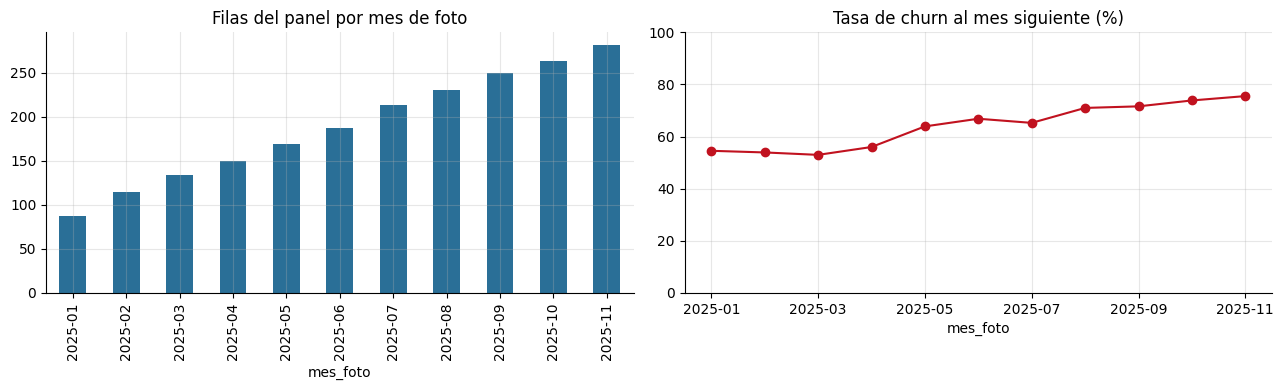

Tasa global de churn: 66.6%


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
resumen = panel.groupby("mes_foto")[TARGET].agg(["size", "mean"])
resumen["size"].plot(kind="bar", ax=ax[0], color="#2a6f97"); ax[0].set_title("Filas del panel por mes de foto")
resumen["mean"].mul(100).plot(ax=ax[1], marker="o", color="#c1121f")
ax[1].set_title("Tasa de churn al mes siguiente (%)"); ax[1].set_ylim(0, 100)
guardar("05_target_por_mes")
plt.show()
print(f"Tasa global de churn: {panel[TARGET].mean():.1%}")

**Insight:** la tasa de churn sube a lo largo del año (de ~54 % a ~75 %). Esto pasa porque el panel acumula clientes que compraron una vez y no volvieron. Hay **desbalance moderado** a favor de la clase positiva, y la distribución del target **no es estacionaria**: es otro motivo para validar con un esquema temporal y no con una partición aleatoria.

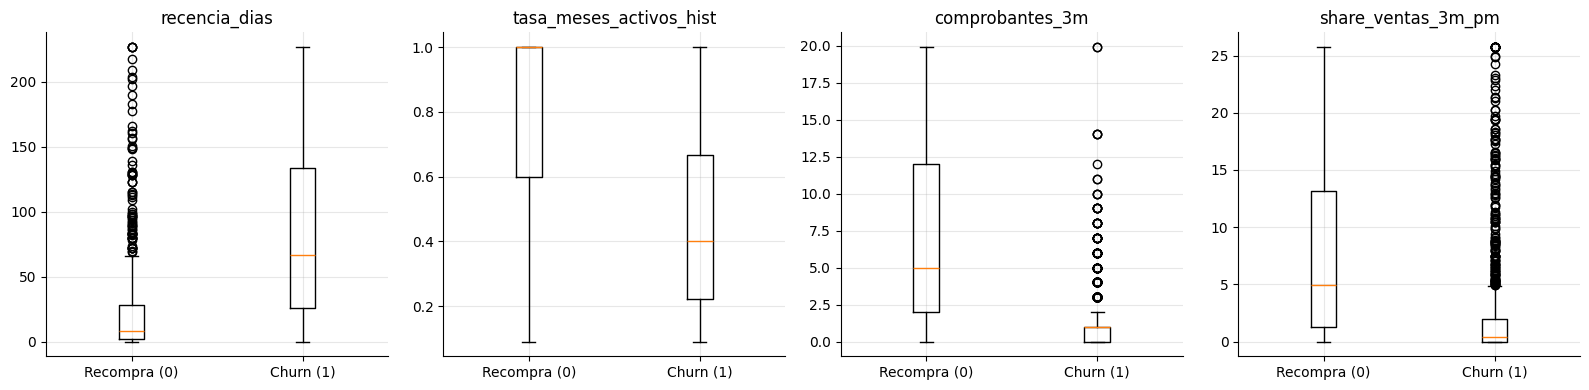

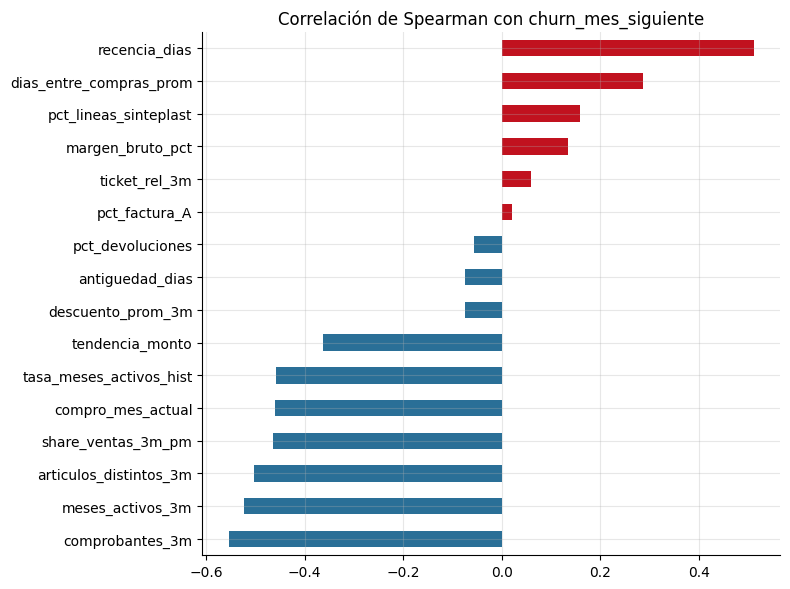

In [11]:
# Relación univariada de los principales features con el target
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, col in zip(ax, ["recencia_dias", "tasa_meses_activos_hist", "comprobantes_3m", "share_ventas_3m_pm"]):
    datos = [panel.loc[panel[TARGET] == k, col].clip(upper=panel[col].quantile(0.95)) for k in (0, 1)]
    a.boxplot(datos, labels=["Recompra (0)", "Churn (1)"])
    a.set_title(col)
guardar("06_features_vs_target")
plt.show()

corr = panel[FEATURES_NUM + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
corr.plot(kind="barh", figsize=(8, 6), color=np.where(corr > 0, "#c1121f", "#2a6f97"),
          title="Correlación de Spearman con churn_mes_siguiente")
guardar("07_correlaciones_target")
plt.show()

## 7. Esquema de validación temporal

Como el objetivo es predecir **el futuro**, la validación tiene que respetar el tiempo:
- **Train:** fotos de enero a septiembre (predicen la recompra de febrero a octubre).
- **Test (hold-out):** fotos de octubre y noviembre (predicen noviembre y diciembre). **No se tocan hasta la evaluación final.**
- **Validación cruzada (dentro de train):** *walk-forward* con ventana expansiva. Se entrena con los meses anteriores a *m* y se valida en *m*, para *m* = junio, julio, agosto y septiembre.

Una partición aleatoria (`KFold` común) mezclaría fotos futuras de un mismo cliente en el entrenamiento, y las métricas quedarían infladas.

In [12]:
ULTIMO_MES_TRAIN = "2025-09"
MESES_VALIDACION = ["2025-06", "2025-07", "2025-08", "2025-09"]

train, test = split_temporal(panel, ULTIMO_MES_TRAIN)
X_COLS = FEATURES_NUM + FEATURES_CAT
X_train, y_train = train[X_COLS], train[TARGET]
X_test, y_test = test[X_COLS], test[TARGET]
CV = cv_ventana_expansiva(train, MESES_VALIDACION)

print(f"Train: {len(train):,} filas (churn {y_train.mean():.1%}) | Test: {len(test):,} filas (churn {y_test.mean():.1%})")
for i, (tr, va) in enumerate(CV, 1):
    print(f"  Fold {i}: entrena {len(tr):,} filas -> valida {len(va)} filas ({MESES_VALIDACION[i-1]})")

Train: 1,537 filas (churn 63.8%) | Test: 546 filas (churn 74.7%)
  Fold 1: entrena 656 filas -> valida 187 filas (2025-06)
  Fold 2: entrena 843 filas -> valida 213 filas (2025-07)
  Fold 3: entrena 1,056 filas -> valida 231 filas (2025-08)
  Fold 4: entrena 1,287 filas -> valida 250 filas (2025-09)


## 8. Entrenamiento y optimización de hiperparámetros

Se comparan cinco enfoques, de menor a mayor complejidad:
1. **Dummy:** predice siempre la proporción de clases. Es el piso.
2. **Regla de negocio:** ordenar por `recencia_dias` ("más días sin comprar, más riesgo"). Es lo que haría un vendedor sin modelo.
3. **Regresión logística:** lineal e interpretable.
4. **Random Forest:** ensamble de árboles, captura no linealidades.
5. **XGBoost:** gradient boosting.

Cada modelo es un `Pipeline` (preprocesamiento + estimador), así que la imputación y el escalado se ajustan dentro de cada fold. Los hiperparámetros se optimizan con **`GridSearchCV`** usando la validación *walk-forward* y **ROC-AUC** como métrica.

In [13]:
# Baselines
dummy = Pipeline([("pre", crear_preprocesador(FEATURES_NUM, FEATURES_CAT)),
                  ("modelo", DummyClassifier(strategy="prior"))]).fit(X_train, y_train)

auc_regla_cv = np.mean([roc_auc_score(y_train.iloc[va], X_train["recencia_dias"].iloc[va]) for _, va in CV])
print(f"Regla de recencia — ROC-AUC CV: {auc_regla_cv:.3f}")

Regla de recencia — ROC-AUC CV: 0.825


In [14]:
espacios = {
    "Regresión logística": (
        LogisticRegression(max_iter=5000, random_state=SEED), True,
        {"modelo__C": [0.01, 0.1, 1, 10], "modelo__class_weight": [None, "balanced"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1), False,
        {"modelo__n_estimators": [300], "modelo__max_depth": [3, 5, 8, None],
         "modelo__min_samples_leaf": [1, 5, 20], "modelo__max_features": ["sqrt", 0.5]}),
    "XGBoost": (
        XGBClassifier(random_state=SEED, eval_metric="logloss", n_jobs=4), False,
        {"modelo__n_estimators": [100, 300], "modelo__max_depth": [2, 3, 5],
         "modelo__learning_rate": [0.03, 0.1], "modelo__subsample": [0.8, 1.0],
         "modelo__min_child_weight": [1, 5]}),
}

busquedas = {}
for nombre, (estimador, escalar, grilla) in espacios.items():
    pipe = Pipeline([("pre", crear_preprocesador(FEATURES_NUM, FEATURES_CAT, escalar=escalar)),
                     ("modelo", estimador)])
    gs = GridSearchCV(pipe, grilla, cv=CV, scoring="roc_auc", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    print(f"{nombre:<20} ROC-AUC CV = {gs.best_score_:.3f} ± {gs.cv_results_['std_test_score'][gs.best_index_]:.3f} "
          f"| {len(gs.cv_results_['params'])} combinaciones")
    print(f"{'':<20} mejores parámetros: { {k.replace('modelo__', ''): v for k, v in gs.best_params_.items()} }")

Regresión logística  ROC-AUC CV = 0.855 ± 0.025 | 8 combinaciones
                     mejores parámetros: {'C': 0.1, 'class_weight': 'balanced'}


Random Forest        ROC-AUC CV = 0.860 ± 0.018 | 24 combinaciones
                     mejores parámetros: {'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 20, 'n_estimators': 300}


XGBoost              ROC-AUC CV = 0.860 ± 0.018 | 48 combinaciones
                     mejores parámetros: {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 100, 'subsample': 1.0}


## 9. Selección y evaluación del modelo

### 9.1 Comparación de modelos (validación y test)

In [15]:
filas = []
filas.append({"Modelo": "Dummy", "ROC_AUC_CV": 0.5,
              **{f"{k}_test": v for k, v in metricas(y_test, dummy.predict_proba(X_test)[:, 1]).items()
                 if k in ("ROC_AUC", "PR_AUC")}})
score_regla = X_test["recencia_dias"] / X_test["recencia_dias"].max()
filas.append({"Modelo": "Regla recencia", "ROC_AUC_CV": auc_regla_cv,
              **{f"{k}_test": v for k, v in metricas(y_test, score_regla).items() if k in ("ROC_AUC", "PR_AUC")}})
for nombre, gs in busquedas.items():
    p = gs.predict_proba(X_test)[:, 1]
    filas.append({"Modelo": nombre, "ROC_AUC_CV": gs.best_score_,
                  **{f"{k}_test": v for k, v in metricas(y_test, p).items() if k in ("ROC_AUC", "PR_AUC")}})
comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion

,ROC_AUC_CV,ROC_AUC_test,PR_AUC_test
Modelo,,,
Dummy,0.500,0.500,0.747
Regla recencia,0.825,0.821,0.917
Regresión logística,0.855,0.852,0.929
Random Forest,0.860,0.857,0.934
XGBoost,0.860,0.862,0.934


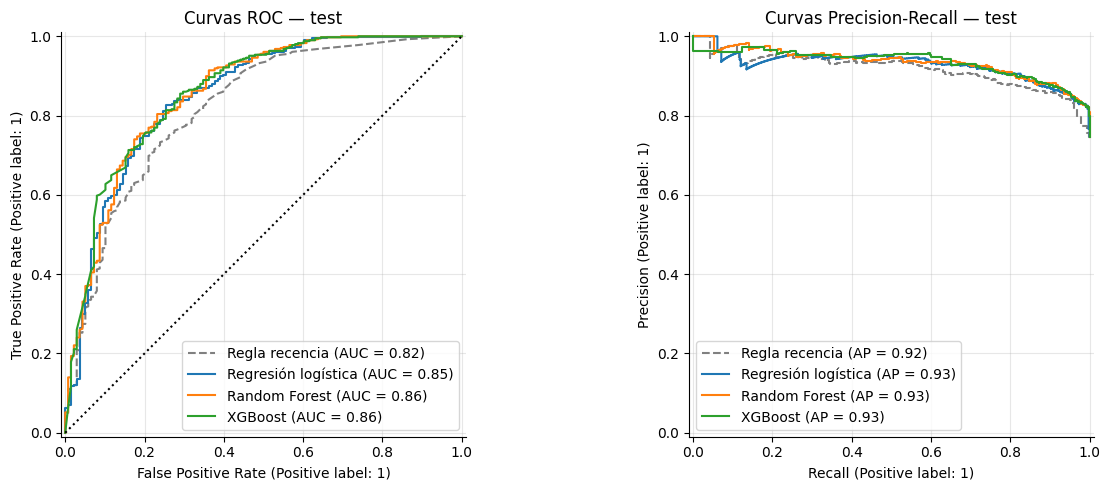

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, score_regla, name="Regla recencia", ax=ax[0], ls="--", color="grey")
PrecisionRecallDisplay.from_predictions(y_test, score_regla, name="Regla recencia", ax=ax[1], ls="--", color="grey")
for nombre, gs in busquedas.items():
    p = gs.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, p, name=nombre, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=nombre, ax=ax[1])
ax[0].plot([0, 1], [0, 1], ":", c="black"); ax[0].set_title("Curvas ROC — test")
ax[1].set_title("Curvas Precision-Recall — test")
guardar("08_roc_pr_test")
plt.show()

### 9.2 Selección

In [17]:
# Criterio: mejor ROC-AUC en validación cruzada (el test NO se usa para elegir)
modelos_ml = comparacion.loc[list(busquedas)]
NOMBRE_FINAL = modelos_ml["ROC_AUC_CV"].idxmax()
modelo_final = busquedas[NOMBRE_FINAL].best_estimator_
print(f"Modelo seleccionado: {NOMBRE_FINAL}")
print(f"  ROC-AUC CV   = {comparacion.loc[NOMBRE_FINAL, 'ROC_AUC_CV']:.3f}")
print(f"  ROC-AUC test = {comparacion.loc[NOMBRE_FINAL, 'ROC_AUC_test']:.3f} "
      f"(vs. regla de recencia {comparacion.loc['Regla recencia', 'ROC_AUC_test']:.3f})")

Modelo seleccionado: XGBoost
  ROC-AUC CV   = 0.860
  ROC-AUC test = 0.862 (vs. regla de recencia 0.821)


### 9.3 Punto de operación (umbral de negocio)

El umbral se fija con predicciones **fuera de muestra** de los folds de validación, nunca con el test. Se busca el umbral más alto que capture **al menos el 80 % de los clientes que se van** (recall ≥ 0,80); de esa forma la lista de contacto queda lo más precisa posible dentro de esa cobertura.

In [18]:
# Predicciones out-of-fold del modelo final sobre los meses de validación
oof_y, oof_p = [], []
for tr, va in CV:
    m = sklearn.base.clone(modelo_final).fit(X_train.iloc[tr], y_train.iloc[tr])
    oof_y.append(y_train.iloc[va]); oof_p.append(m.predict_proba(X_train.iloc[va])[:, 1])
oof_y, oof_p = np.concatenate(oof_y), np.concatenate(oof_p)

UMBRAL = umbral_para_recall(oof_y, oof_p, recall_objetivo=0.80)
print(f"Umbral elegido: {UMBRAL:.2f}")

proba_test = modelo_final.predict_proba(X_test)[:, 1]
met_test = metricas(y_test, proba_test, UMBRAL)
met_regla = metricas(y_test, score_regla, umbral_para_recall(y_train, X_train["recencia_dias"] / X_train["recencia_dias"].max()))
pd.DataFrame({NOMBRE_FINAL: met_test, "Regla recencia": met_regla}).T

Umbral elegido: 0.68


,ROC_AUC,PR_AUC,Precision,Recall,F1
XGBoost,0.862,0.934,0.896,0.843,0.869
Regla recencia,0.821,0.917,0.865,0.860,0.862


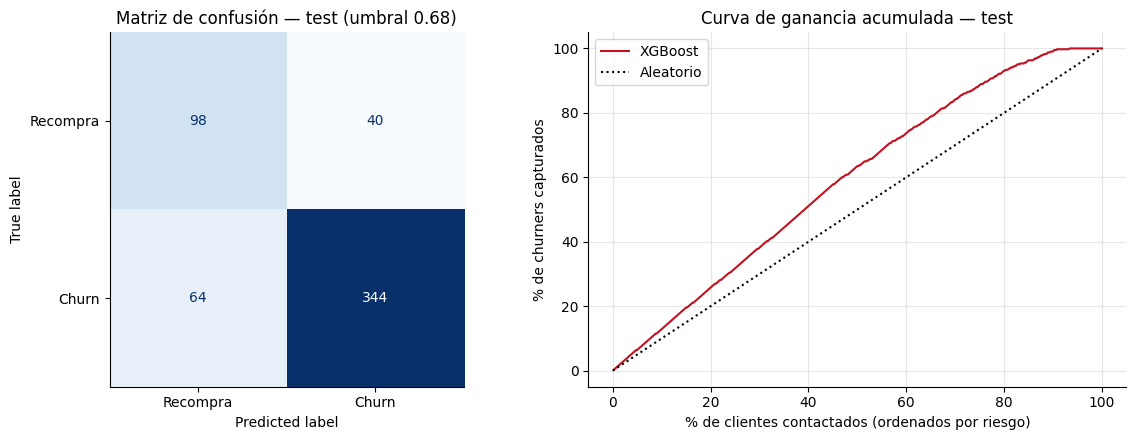

Contactando al 30 % de mayor riesgo se captura el 38% de los que se van (máximo posible: 40%). Precisión en ese grupo: 95% vs. tasa base 75%.


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, (proba_test >= UMBRAL).astype(int)),
                       display_labels=["Recompra", "Churn"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Matriz de confusión — test (umbral {UMBRAL:.2f})"); ax[0].grid(False)

# Ganancia acumulada: % de churners capturados contactando al X % de clientes de mayor riesgo
orden = np.argsort(-proba_test)
captura = np.cumsum(y_test.values[orden]) / y_test.sum()
pct = np.arange(1, len(orden) + 1) / len(orden)
ax[1].plot(pct * 100, captura * 100, label=NOMBRE_FINAL, color="#c1121f")
ax[1].plot([0, 100], [0, 100], ":", c="black", label="Aleatorio")
ax[1].set_xlabel("% de clientes contactados (ordenados por riesgo)"); ax[1].set_ylabel("% de churners capturados")
ax[1].set_title("Curva de ganancia acumulada — test"); ax[1].legend()
guardar("09_confusion_ganancia")
plt.show()

top = int(len(orden) * 0.3)
print(f"Contactando al 30 % de mayor riesgo se captura el {captura[top-1]:.0%} de los que se van "
      f"(máximo posible: {min(1, top / y_test.sum()):.0%}). Precisión en ese grupo: "
      f"{y_test.values[orden][:top].mean():.0%} vs. tasa base {y_test.mean():.0%}.")

In [20]:
# Estabilidad: desempeño por mes de test
pd.DataFrame({
    m: metricas(y_test[test["mes_foto"] == m], proba_test[test["mes_foto"] == m], UMBRAL)
    for m in test["mes_foto"].unique()
}).T

,ROC_AUC,PR_AUC,Precision,Recall,F1
2025-10,0.839,0.918,0.869,0.815,0.841
2025-11,0.886,0.950,0.920,0.869,0.894


## 10. Interpretabilidad con SHAP

Se usa **SHAP** (*SHapley Additive exPlanations*) para descomponer cada predicción en la contribución de cada feature. Esto permite validar que el modelo aprendió patrones con sentido de negocio y explicar a un vendedor **por qué** un cliente aparece como "en riesgo".

In [21]:
pre_final = modelo_final.named_steps["pre"]
est_final = modelo_final.named_steps["modelo"]
nombres = [n.replace("num__", "").replace("cat__", "") for n in pre_final.get_feature_names_out()]
Xt_train = pd.DataFrame(pre_final.transform(X_train), columns=nombres)
Xt_test = pd.DataFrame(pre_final.transform(X_test), columns=nombres)

if isinstance(est_final, LogisticRegression):
    explainer = shap.LinearExplainer(est_final, Xt_train)
else:
    explainer = shap.TreeExplainer(est_final)
sv = explainer(Xt_test)
if sv.values.ndim == 3:            # Random Forest devuelve una matriz por clase
    sv = sv[:, :, 1]
print(f"Explicando {NOMBRE_FINAL} sobre {len(Xt_test)} observaciones de test")

Explicando XGBoost sobre 546 observaciones de test


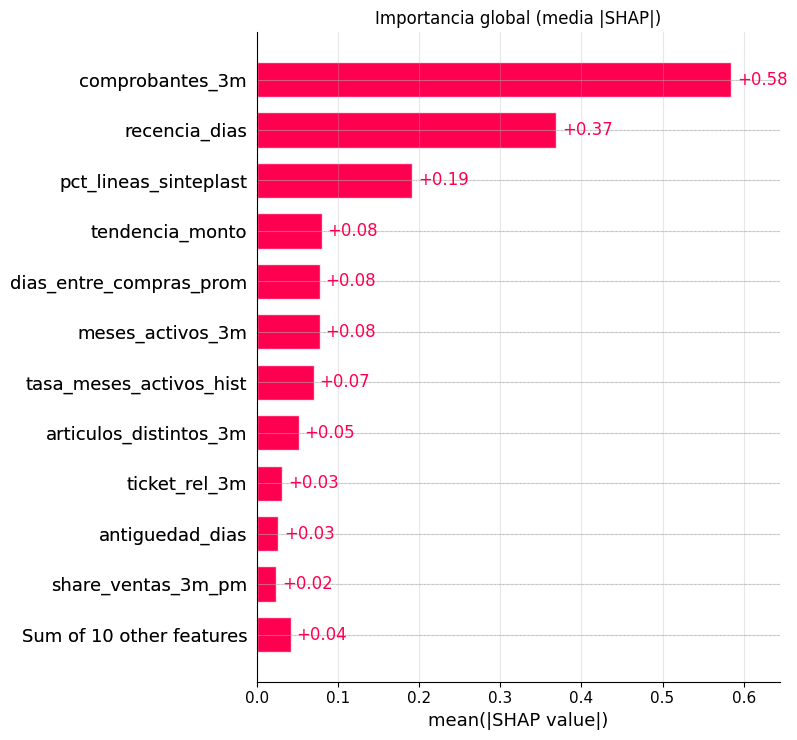

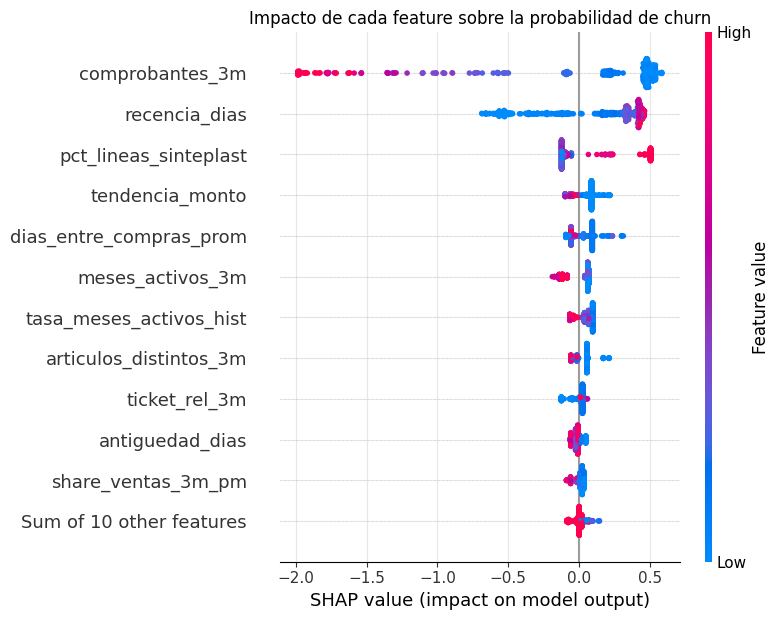

In [22]:
plt.figure()
shap.plots.bar(sv, max_display=12, show=False)
plt.title("Importancia global (media |SHAP|)")
guardar("10_shap_importancia")
plt.show()

plt.figure()
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Impacto de cada feature sobre la probabilidad de churn")
guardar("11_shap_beeswarm")
plt.show()

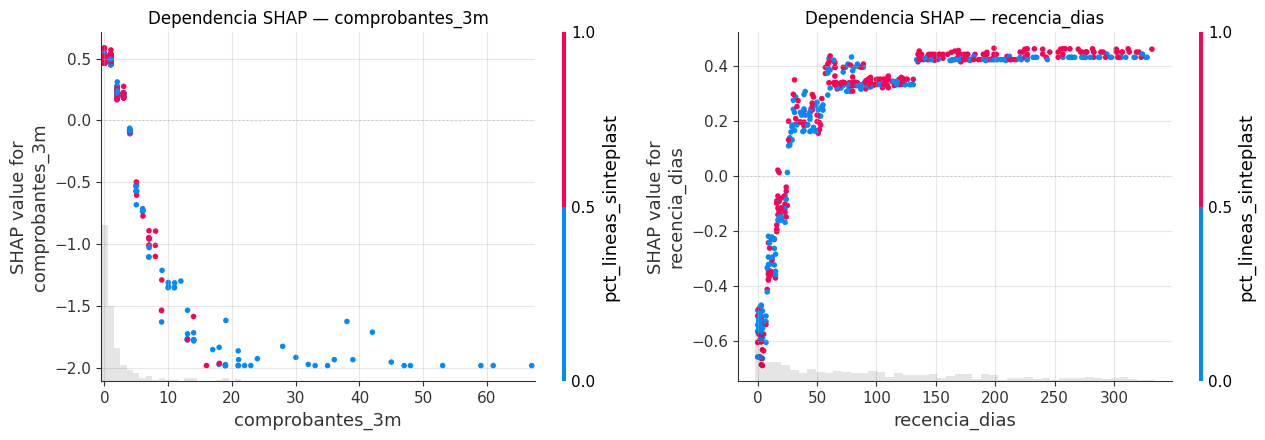

In [23]:
# Dependencia: cómo cambia el riesgo con las dos variables más importantes
top2 = pd.Series(np.abs(sv.values).mean(0), index=nombres).nlargest(2).index
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, f in zip(ax, top2):
    shap.plots.scatter(sv[:, f], ax=a, show=False, color=sv)
    a.set_title(f"Dependencia SHAP — {f}")
guardar("12_shap_dependencia")
plt.show()

Cliente C_9db4433423 | foto 2025-11 | prob. churn = 88% | real = churn


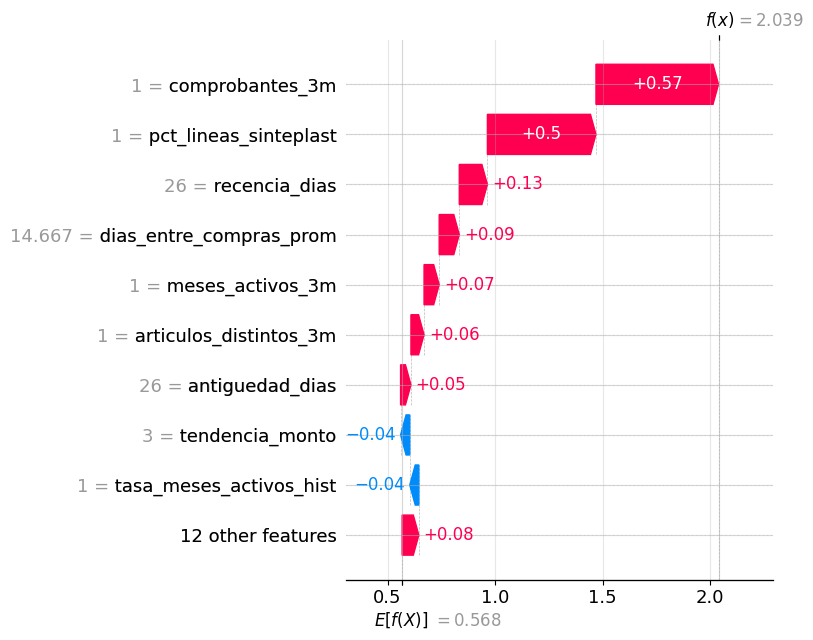

In [24]:
# Explicación local: el cliente de mayor riesgo que SÍ venía comprando en el mes de la foto
cand = np.where((X_test["compro_mes_actual"] == 1).values)[0]
idx = cand[np.argmax(proba_test[cand])]
print(f"Cliente {test.loc[idx, 'ID_CLIENTE']} | foto {test.loc[idx, 'mes_foto']} | "
      f"prob. churn = {proba_test[idx]:.0%} | real = {'churn' if y_test.iloc[idx] else 'recompra'}")
plt.figure()
shap.plots.waterfall(sv[idx], max_display=10, show=False)
guardar("13_shap_waterfall_cliente")
plt.show()

**Lectura de SHAP (ver gráficos):**
- **Frecuencia reciente (`comprobantes_3m`) y recencia** dominan el modelo. Muchos comprobantes en los últimos 3 meses bajan el riesgo; muchos días sin comprar lo suben. Es coherente con la teoría RFM y con la intuición comercial.
- **`pct_lineas_sinteplast` es el tercer factor, y es un hallazgo de negocio:** los clientes cuya compra es casi toda pintura de la marca principal tienen más riesgo de no volver. Probablemente son obras puntuales (pintar una casa). En cambio, los clientes con canasta mixta (lijas, herramientas, otros insumos) son profesionales con demanda continua.
- **`tendencia_monto`** también pesa: un cliente que este mes compró por encima de su promedio reciente tiene menos riesgo, y uno que viene cayendo, más.
- Estas variables agregan señal más allá de la recencia. Por eso el modelo supera a la regla simple, sobre todo para distinguir entre clientes con recencia parecida.
- El gráfico *waterfall* muestra cómo se explica un caso individual. Es una herramienta concreta para que el vendedor entienda el motivo antes de llamar al cliente.

In [25]:
# Persistencia del modelo y de las métricas para auditoría / despliegue
joblib.dump({"modelo": modelo_final, "umbral": UMBRAL, "features": X_COLS}, MODELS / "modelo_churn.joblib")
resultados = {
    "modelo_seleccionado": NOMBRE_FINAL,
    "mejores_hiperparametros": {k.replace("modelo__", ""): (v if not isinstance(v, np.generic) else v.item())
                                for k, v in busquedas[NOMBRE_FINAL].best_params_.items()},
    "umbral": UMBRAL,
    "roc_auc_cv": round(float(comparacion.loc[NOMBRE_FINAL, "ROC_AUC_CV"]), 4),
    "test": {k: round(float(v), 4) for k, v in met_test.items()},
    "test_regla_recencia": {k: round(float(v), 4) for k, v in met_regla.items()},
    "comparacion": comparacion.round(4).reset_index().to_dict(orient="records"),
}
(ROOT / "reports" / "metricas.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False))
print(json.dumps(resultados["test"], indent=2))

{
  "ROC_AUC": 0.8623,
  "PR_AUC": 0.9342,
  "Precision": 0.8958,
  "Recall": 0.8431,
  "F1": 0.8687
}


## 11. Conclusiones, recomendaciones y limitaciones

**Resultados**
- El modelo seleccionado es **XGBoost** (árboles poco profundos: `max_depth=2`, `learning_rate=0.03`, 100 árboles), elegido por el mejor ROC-AUC en la validación *walk-forward* (**0,860**). En el período de test (nov-dic 2025, nunca visto) obtiene **ROC-AUC 0,862 y PR-AUC 0,934**, sin señales de sobreajuste: CV y test son prácticamente iguales.
- Supera a la **regla de recencia** (ROC-AUC 0,821) y al baseline dummy (0,50). Random Forest queda prácticamente empatado (0,857 en test) y la regresión logística apenas por debajo (0,852). La ganancia de los modelos complejos sobre el lineal es modesta, lo esperable con un dataset de ~2.000 filas.
- En el punto de operación (umbral 0,68, fijado en validación para recall ≥ 80 %) el modelo detecta al **84 % de los clientes que no vuelven, con 90 % de precisión** en test.

**Justificación de negocio de la elección**
- La mejora sobre la regla simple está, sobre todo, en el **ordenamiento** (+4 puntos de AUC) y en la **precisión** (+3 puntos con un recall similar). En la práctica, la lista de contacto prioriza mejor a quién llamar primero y tiene menos llamados "en vano".
- XGBoost es explicable con SHAP. Cada cliente marcado puede ir acompañado de sus motivos (por ejemplo: "no compra hace 60 días y bajó su frecuencia"), y eso facilita que el equipo comercial confíe en el modelo y lo adopte.
- Si se prioriza simplicidad operativa, la regresión logística es una alternativa válida con una pérdida mínima de desempeño.

**Recomendaciones**
1. Correr el modelo **al cierre de cada mes** y entregar a los vendedores el listado de clientes con probabilidad ≥ 0,68, ordenado por riesgo × facturación (el Pareto muestra que el 20 % de los clientes explica el 83 % de las ventas).
2. Priorizar acciones sobre clientes recurrentes que muestran caída de frecuencia. Los compradores de una sola obra son, en gran parte, churn "natural" y no conviene invertir en ellos.
3. Usar el hallazgo de `pct_lineas_sinteplast` comercialmente: ofrecer complementos (lijas, herramientas, accesorios) a quien sólo compra pintura puede convertirlo en cliente recurrente.

**Limitaciones**
- **Un solo año de datos** y ~300 clientes: no se puede modelar estacionalidad anual, y la antigüedad está censurada a la izquierda (clientes anteriores a enero 2025 aparecen como "nuevos").
- **Inflación:** se mitigó con features relativos al total del local, pero los montos absolutos no son comparables entre meses.
- **Datos ausentes en el sistema:** medio de pago, tipo de venta y marca (salvo Sinteplast) no están cargados, y podrían aportar señal.
- El churn está definido como "no compra el mes siguiente". Para clientes de ciclo largo (compran cada 2-3 meses) es una definición exigente; una variante con ventana de 60-90 días es un buen próximo paso.

**Próximos pasos:** incorporar más historia (2024), probar una ventana de churn de 60/90 días, calibrar las probabilidades y medir el impacto real con un experimento (grupo contactado vs. grupo control).